In [417]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange
import copy

import cvxpy as cp
import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import IrrigationSchedulingModel, IrrigationSchedulingCost
from Components.Controllers import TimeVaryingCost_LQRc_RHG
from Components.Solver import fbrs

In [418]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [419]:
parameter_file = "Components/Setup/model_parameters.json"

In [420]:
# Example crop repartition
crops = np.array([[0.5, 0.8, 0.3], [0., 0.2, 0.3], [0.4, 0., 0.3], [0., 0., 0.4]])

In [665]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCost(parameter_file, model, crops)

In [422]:
# Initialize Controller
controller = TimeVaryingCost_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    model.H_xu_x, model.H_xu_u, model.h_xu,
    solver='fbrs'
)

# Crop water demand

In [423]:
water_req = cost_model._get_water_requirement(0, 365)

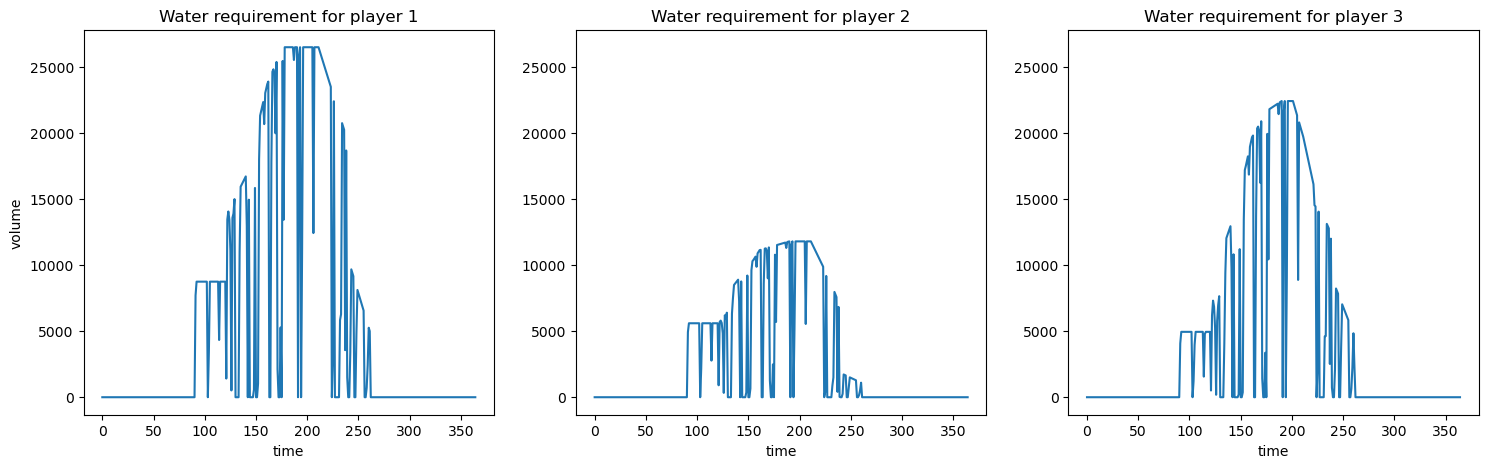

In [424]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Water requirement for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot(water_req[ii, :, :].sum(axis=0))

In [425]:
data = np.load("run_data/run_20250623-101633/result_data.npz")

In [426]:
n_well = int(sum(np.hstack(model.n_well_per_command)))
well_to_agent = np.zeros((model.n_agent, n_well))
indices = np.array(list(zip(model.well_to_agent.tolist(), range(n_well)))).T
well_to_agent[indices[0, :], indices[1, :]] = 1
well_to_agent

array([[1., 0., 0., 1., 0.],
       [0., 0., 1., 0., 1.],
       [0., 1., 0., 0., 0.]])

In [427]:
player_pumping = well_to_agent @ data['q_rates']

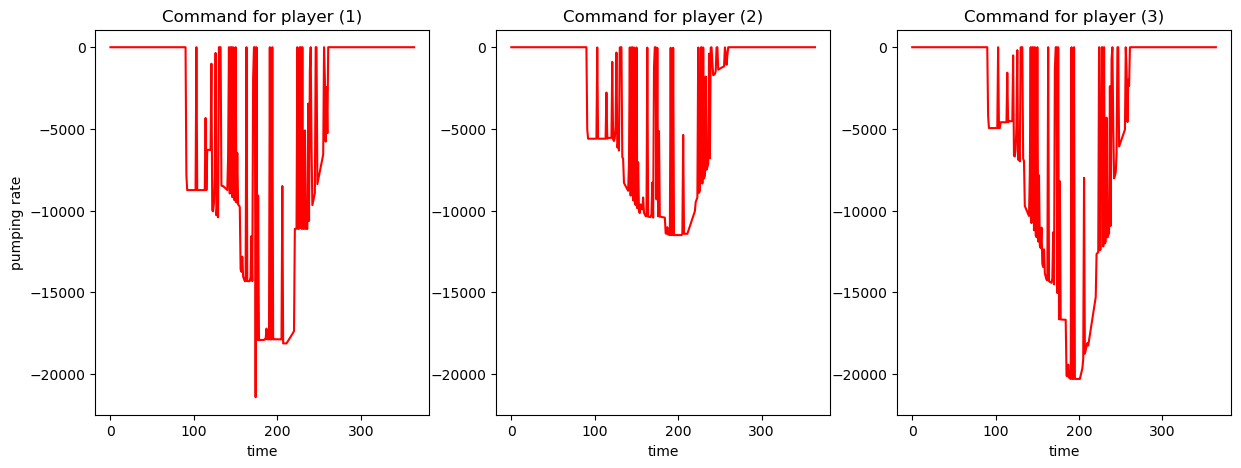

In [428]:
# Display command evolution
fig_q = plt.figure(figsize=(25,5))
ax_q = None
for ii in range(model.n_agent):
    ax_q = fig_q.add_subplot(1, 5, ii+1, sharey=ax_q)
    ttl = f"Command for player ({ii+1})"
    ax_q.set_title(ttl)
    ax_q.set_xlabel("time")
    if ii == 0:
        ax_q.set_ylabel("pumping rate")
    ax_q.plot(player_pumping[ii, :], "r-")

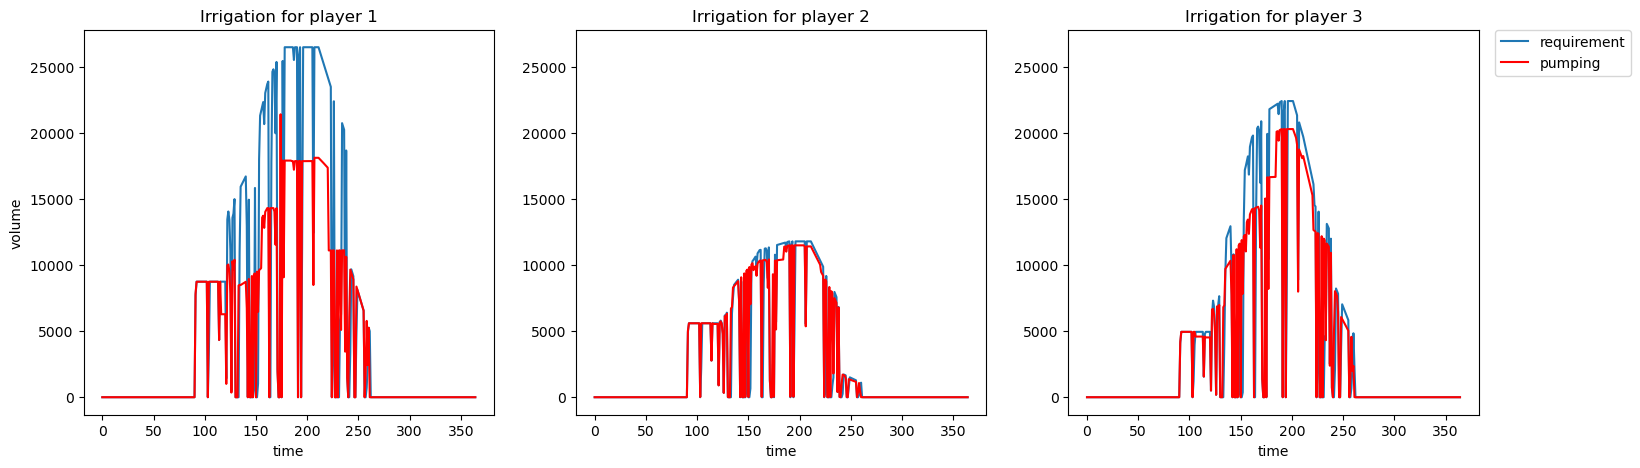

In [429]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Irrigation for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot(water_req[ii, :, :].sum(axis=0), label='requirement')
    ax.plot(-player_pumping[ii, :], "r-", label='pumping')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

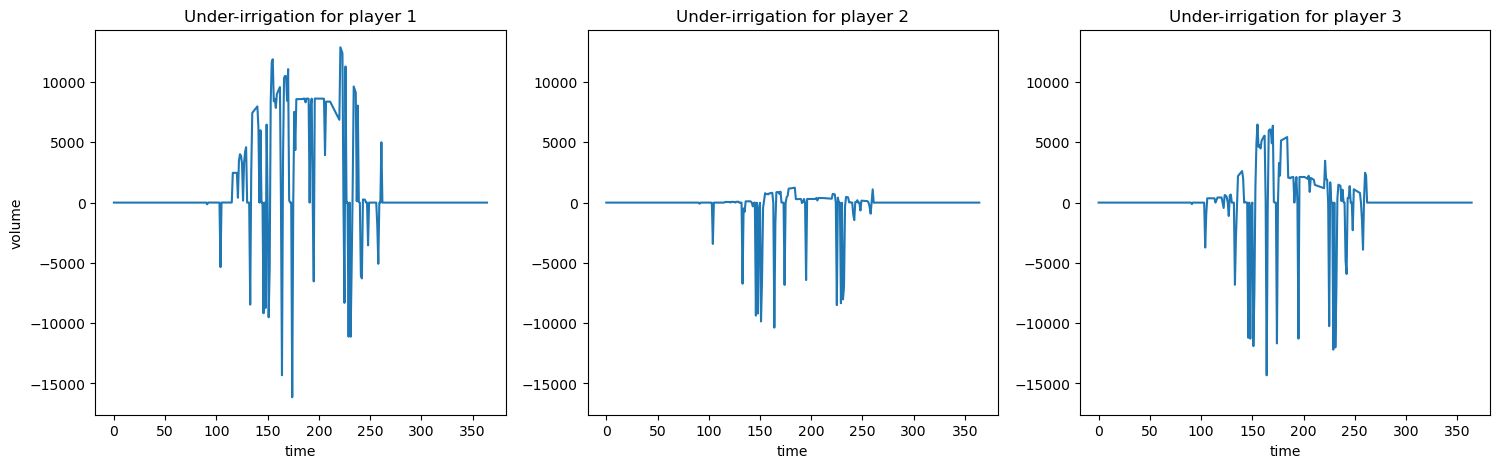

In [430]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Under-irrigation for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot((water_req[ii, :, :].sum(axis=0) + player_pumping[ii,:]))

# Under-irrigation sensibility

In [431]:
under_irrigation_weight = cost_model._get_under_irrigation_weight(0, 365)

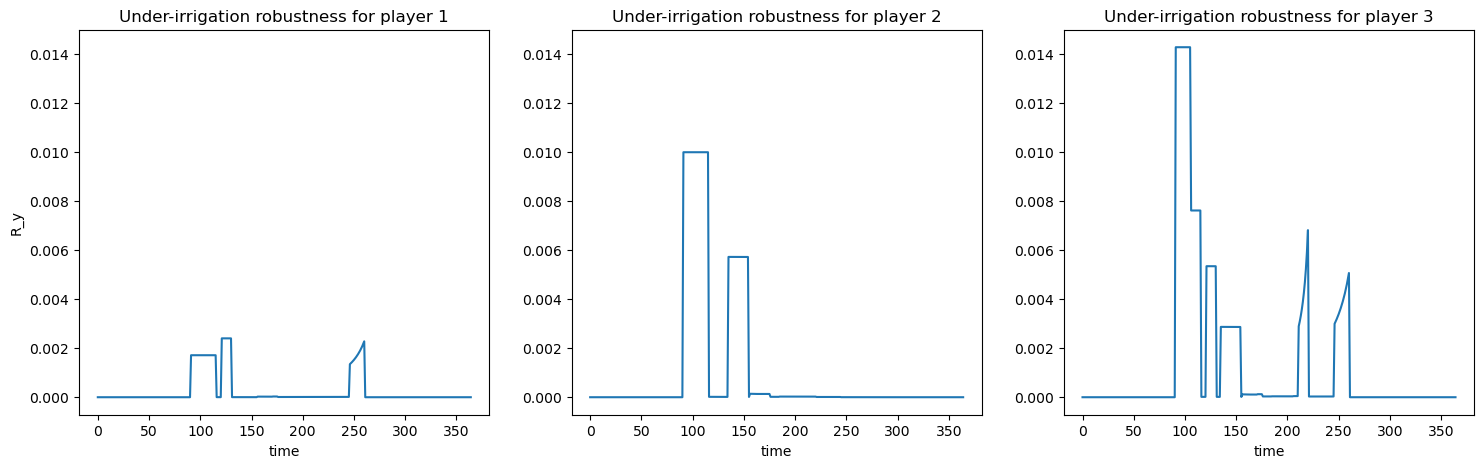

In [432]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Under-irrigation robustness for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("R_y")
    ax.plot(under_irrigation_weight[ii, :, :].sum(axis=0))

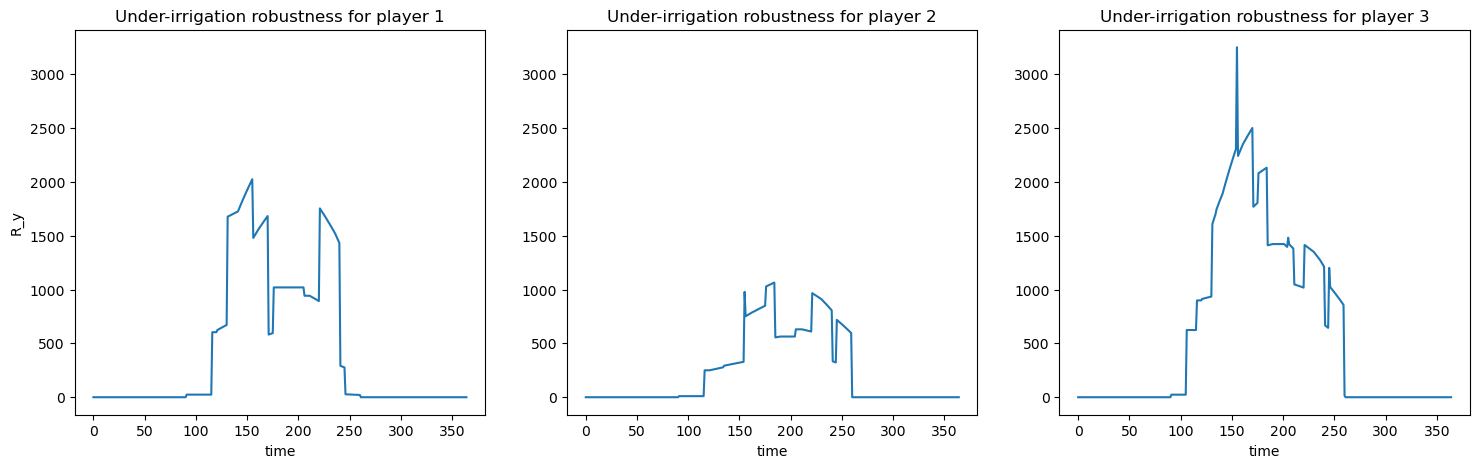

In [433]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Under-irrigation robustness for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("R_y")
    ax.plot(np.sqrt(np.where(under_irrigation_weight !=0, 1/under_irrigation_weight, 0))[ii, :, :].sum(axis=0))

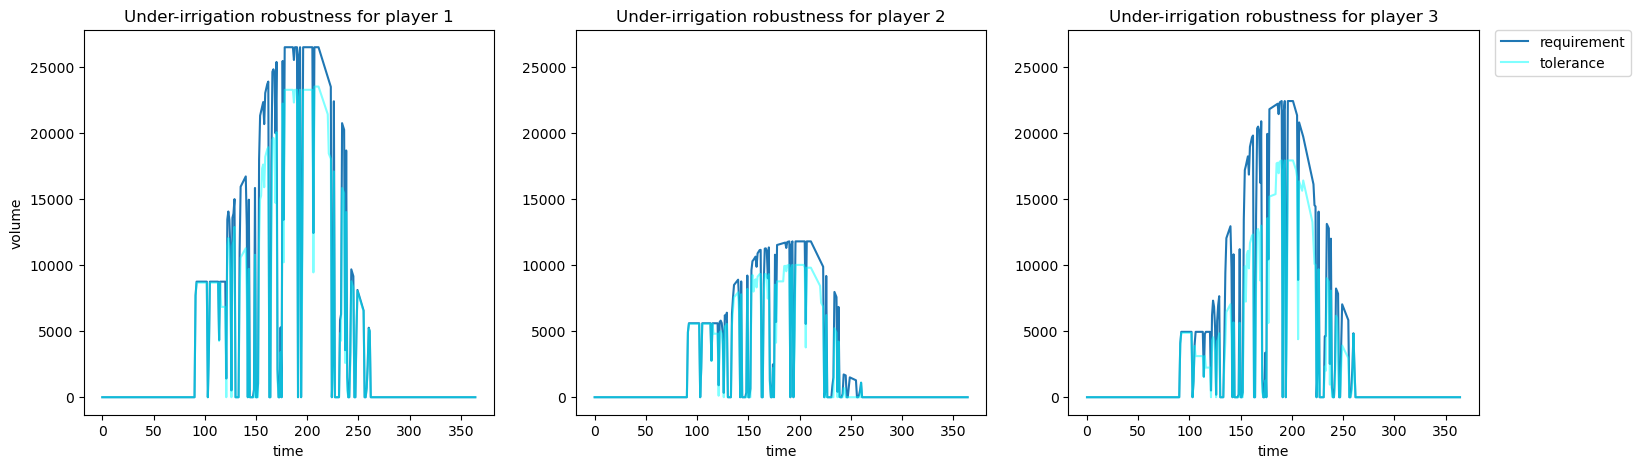

In [434]:
tol = 10
ET_min = np.maximum(water_req - np.sqrt(tol * np.where(under_irrigation_weight !=0, 1/under_irrigation_weight, 0)), 0)

fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Under-irrigation robustness for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot(water_req[ii, :, :].sum(axis=0), label='requirement')
    ax.plot(ET_min[ii, :, :].sum(axis=0), c="cyan", alpha=0.5, label='tolerance')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

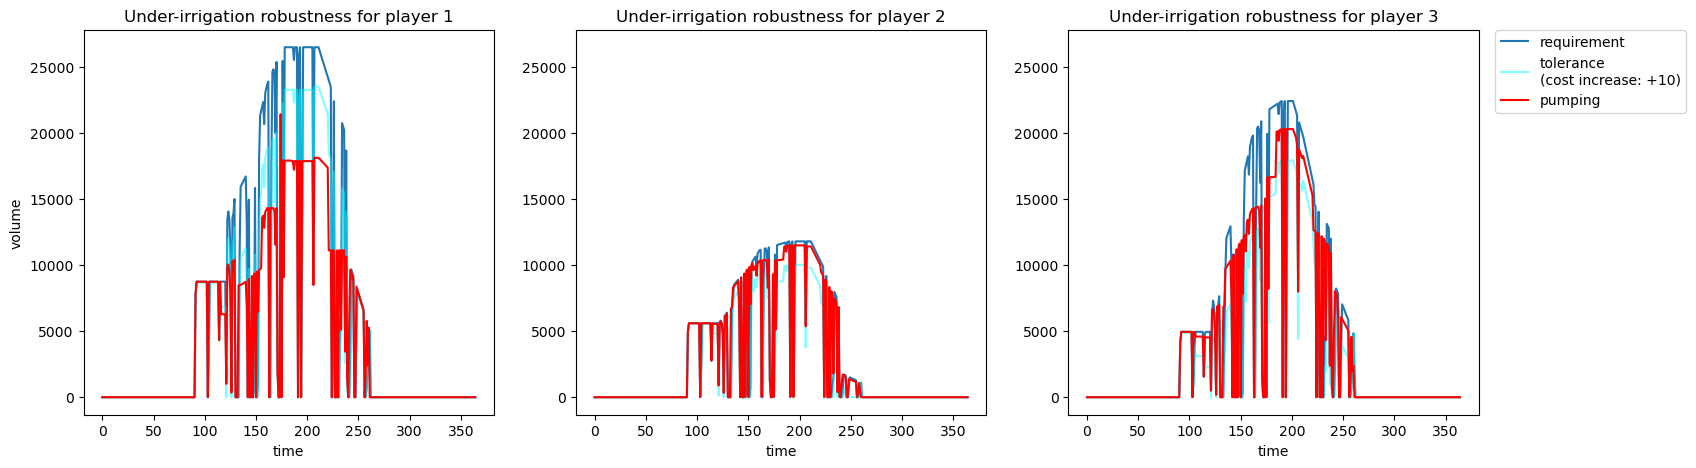

In [435]:
tol = 10
ET_min = np.maximum(water_req - np.sqrt(tol * np.where(under_irrigation_weight !=0, 1/under_irrigation_weight, 0)), 0)

fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Under-irrigation robustness for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot(water_req[ii, :, :].sum(axis=0), label='requirement')
    ax.plot(ET_min[ii, :, :].sum(axis=0), c="cyan", alpha=0.5, label=f'tolerance\n(cost increase: +{tol})')
    ax.plot(-player_pumping[ii, :], "r-", label='pumping')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Irrigation per crop

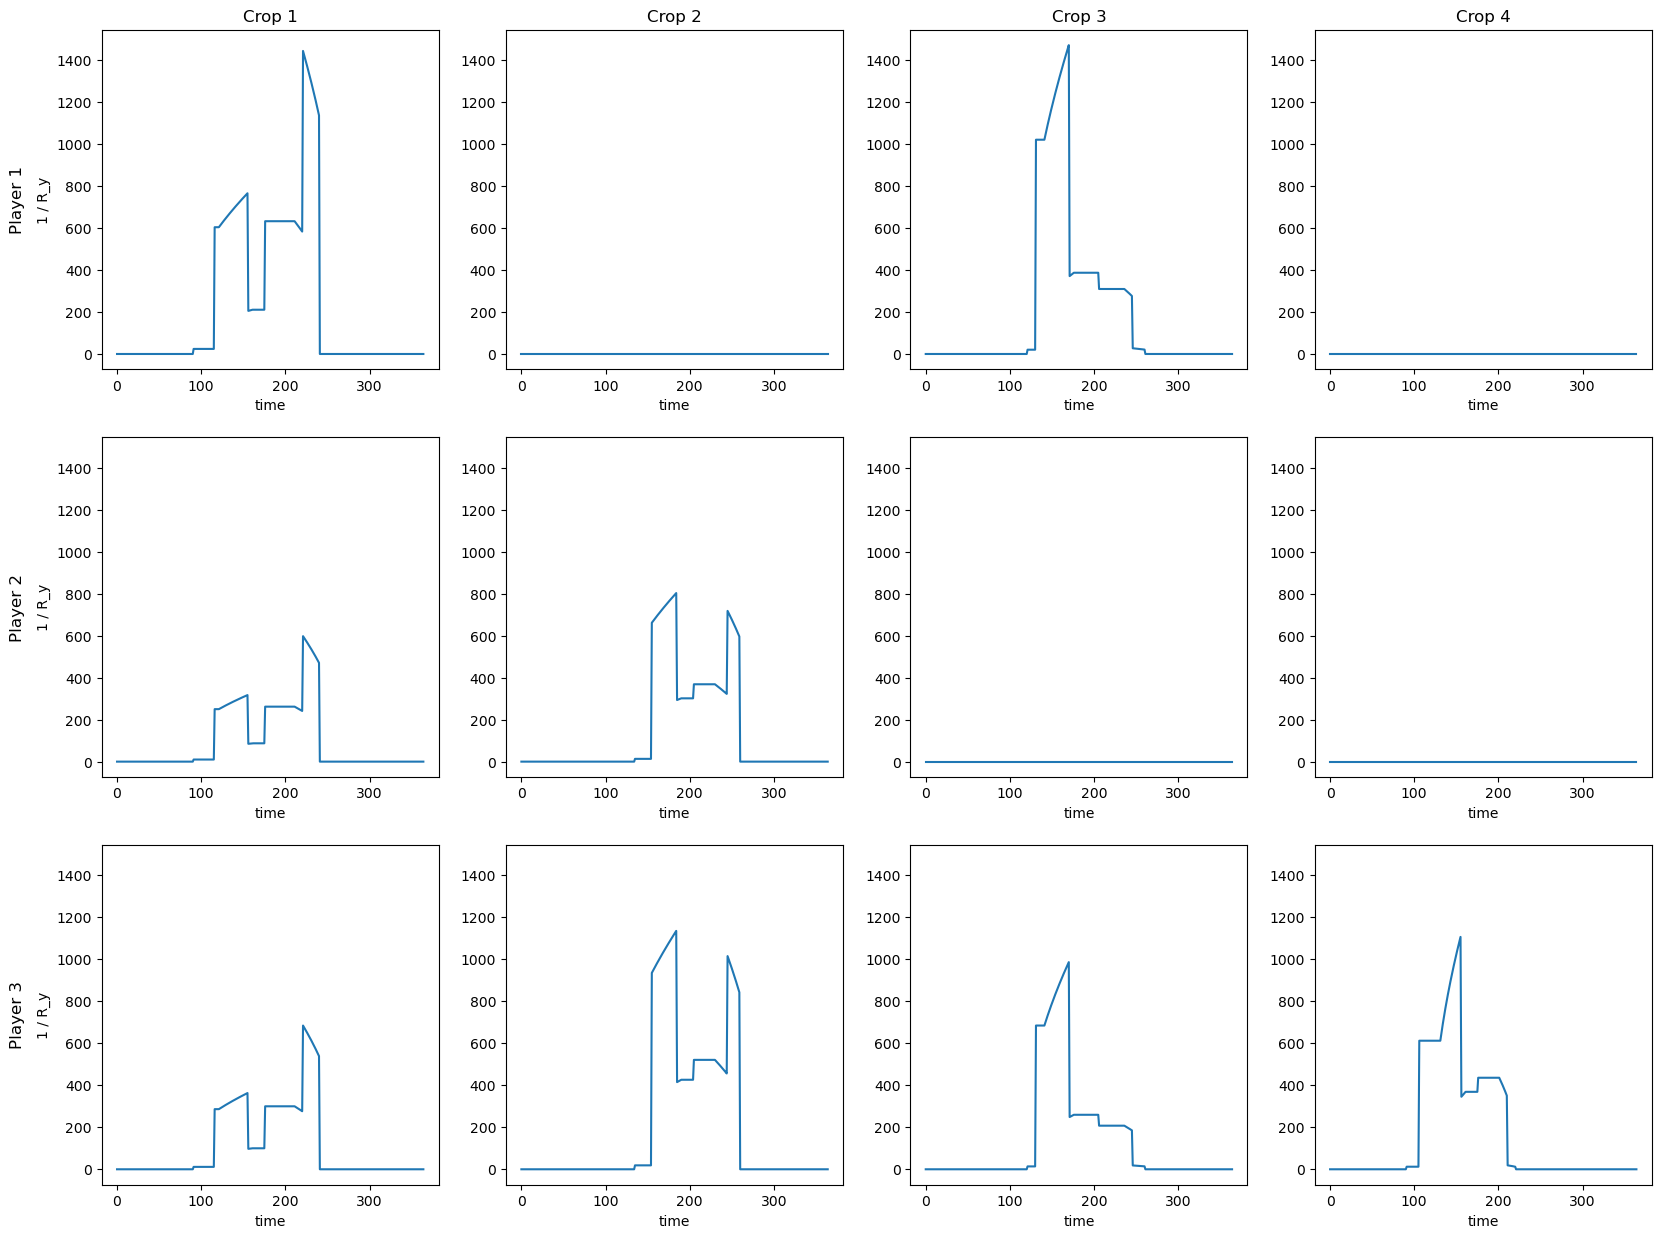

In [436]:
fig = plt.figure(figsize=(15+5,15))
ax = None
for ii in range(3):
    for c in range(model.n_crops):
        ax = fig.add_subplot(3, model.n_crops, model.n_crops*ii+c+1, sharey=ax)
        if ii == 0:
            ax.set_title(f"Crop {c+1}")
        ax.set_xlabel("time")
        if c == 0:
            ax.set_ylabel("1 / R_y")
            ax.annotate(f"Player {ii+1}", xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 10, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='center', va='center', rotation=90)
        ax.plot(np.sqrt(np.where(under_irrigation_weight !=0, 1/under_irrigation_weight, 0))[ii, c, :])

In [437]:
sum_nu_v = np.cumsum([0] + controller.nu_v)
crop_irrigation = np.stack([cost_model.input_to_crop_irrigation_v[v] @ data['inputs'][sum_nu_v[v]:sum_nu_v[v+1]] for v in range(model.n_agent)], axis=2)
crop_irrigation.shape

(4, 365, 3)

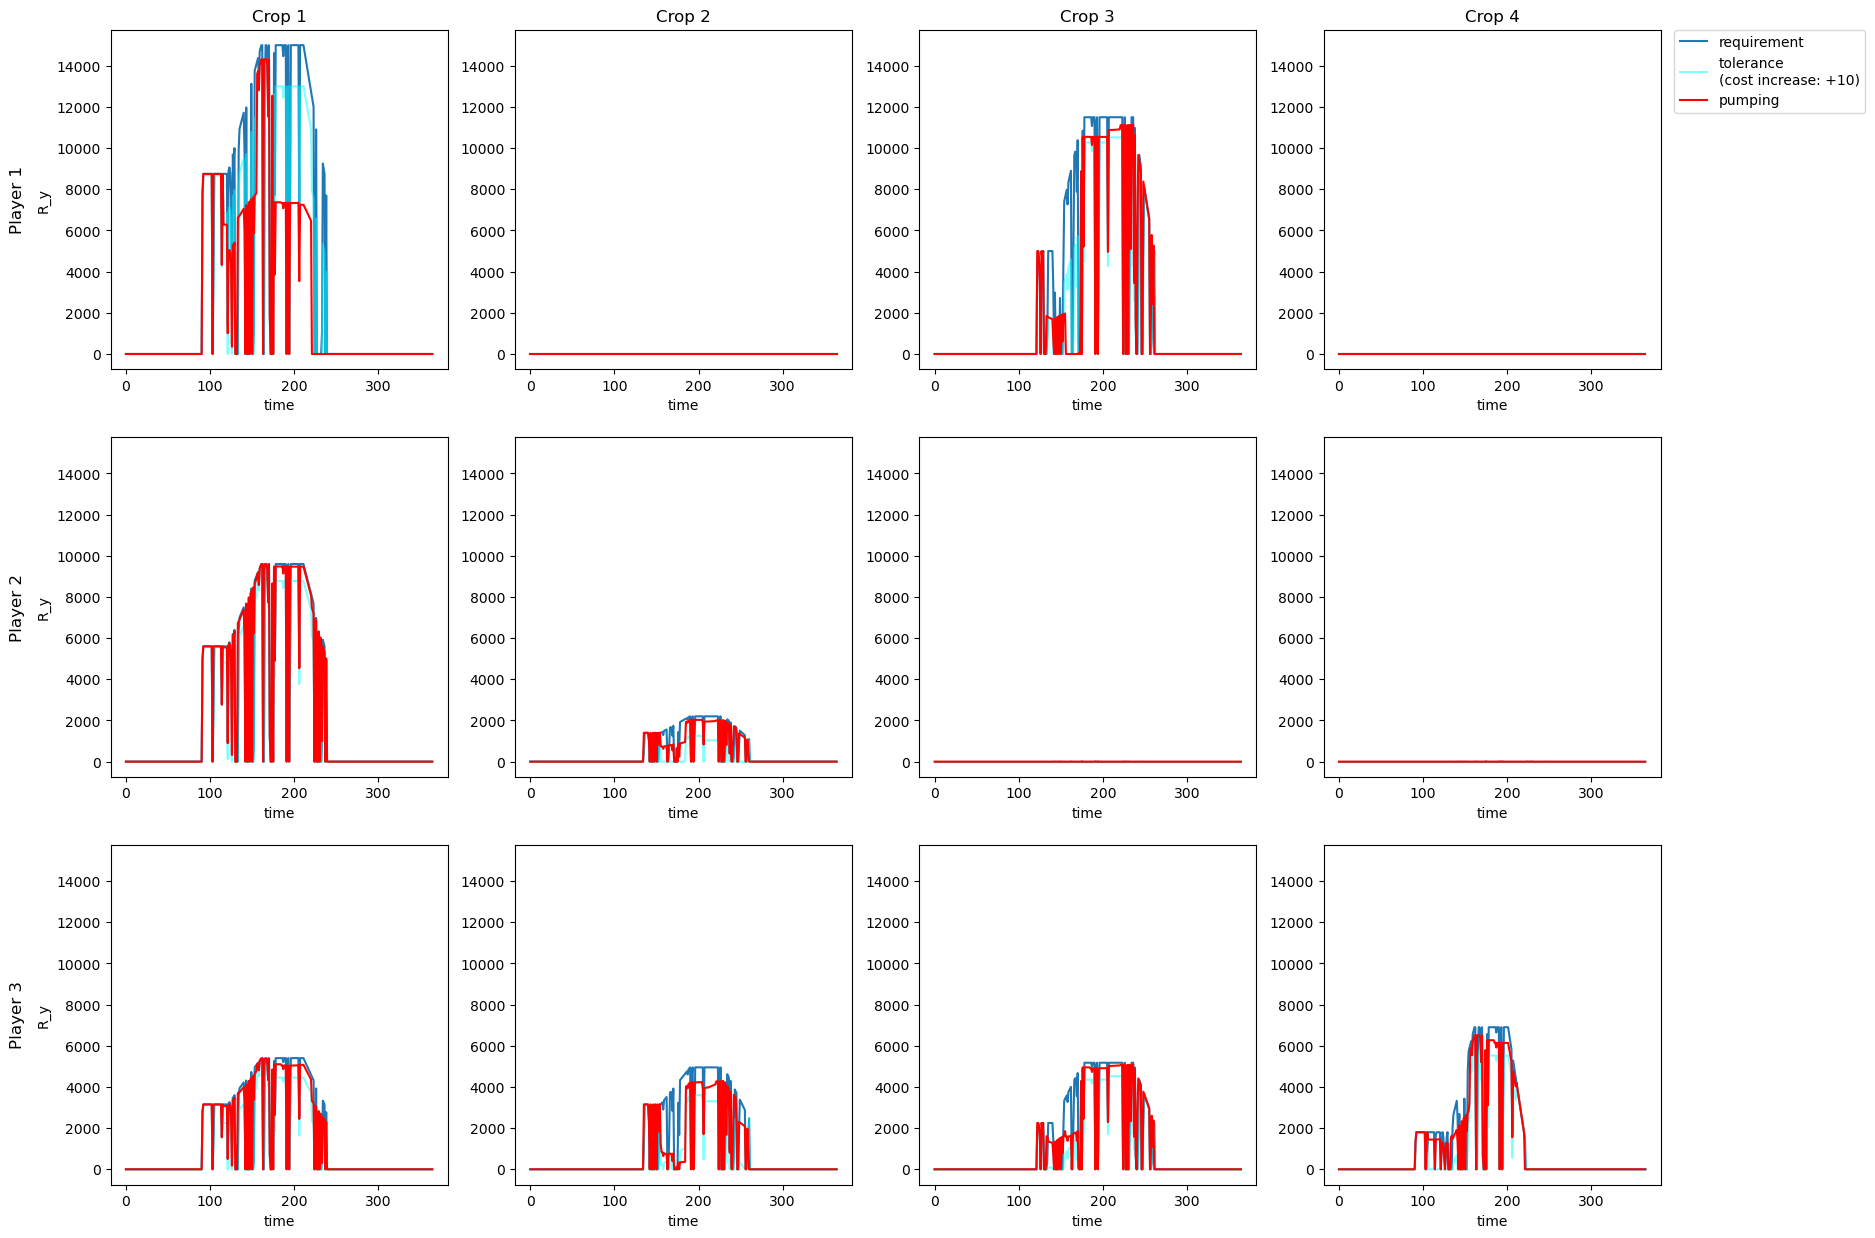

In [438]:
fig = plt.figure(figsize=(15+5,15))
ax = None
for ii in range(3):
    for c in range(model.n_crops):
        ax = fig.add_subplot(3, model.n_crops, model.n_crops*ii+c+1, sharey=ax)
        if ii == 0:
            ax.set_title(f"Crop {c+1}")
        ax.set_xlabel("time")
        if c == 0:
            ax.set_ylabel("R_y")
            ax.annotate(f"Player {ii+1}", xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 10, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='center', va='center', rotation=90)
        ax.plot(water_req[ii, c, :], label='requirement')
        ax.plot(ET_min[ii, c, :], c="cyan", alpha=0.5, label=f'tolerance\n(cost increase: +{tol})')
        ax.plot(-crop_irrigation[c, :, ii], "r-", label='pumping')
        if ii==0 and c==model.n_crops-1:
            ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

#### Greater controller horizon

In [439]:
data_30 = np.load("run_data/run_20250623-113138/result_data.npz")

In [440]:
(data_30['inputs'] == data['inputs']).all()

np.False_

In [441]:
(data_30['inputs'] - data['inputs']).max()

np.float64(0.005745706012930896)

In [442]:
data_3 = np.load("run_data/run_20250623-114458/result_data.npz")

In [443]:
(data_30['inputs'] - data_3['inputs']).max()

np.float64(2.093468285002018)

In [444]:
del data_3, data_30

Does not seem to change a lot. That is a problem fighting against the justification of the use of the dynamical model / receding horizon.

=> hence maybe a motivation to use a (more or less) simple surface water model.

# Change in yield sensitivity

In [445]:
data_ys_3 = np.load("run_data/run_20250623-115947/result_data.npz")
data_ys_5 = np.load("run_data/run_20250623-115638/result_data.npz")
data_ys_8 = np.load("run_data/run_20250623-120303/result_data.npz")
data_ys_10 = np.load("run_data/run_20250623-120628/result_data.npz")

In [446]:
crop_irrigation_ys_3 = np.stack([cost_model.input_to_crop_irrigation_v[v] @ data_ys_3['inputs'][sum_nu_v[v]:sum_nu_v[v+1]] for v in range(model.n_agent)], axis=2)
crop_irrigation_ys_5 = np.stack([cost_model.input_to_crop_irrigation_v[v] @ data_ys_5['inputs'][sum_nu_v[v]:sum_nu_v[v+1]] for v in range(model.n_agent)], axis=2)
crop_irrigation_ys_8 = np.stack([cost_model.input_to_crop_irrigation_v[v] @ data_ys_8['inputs'][sum_nu_v[v]:sum_nu_v[v+1]] for v in range(model.n_agent)], axis=2)
crop_irrigation_ys_10 = np.stack([cost_model.input_to_crop_irrigation_v[v] @ data_ys_10['inputs'][sum_nu_v[v]:sum_nu_v[v+1]] for v in range(model.n_agent)], axis=2)

In [447]:
colors = plt.get_cmap("tab20c")(np.arange(20))
colors = np.concatenate([colors, [[255/255, 69/255, 0, 1]]])

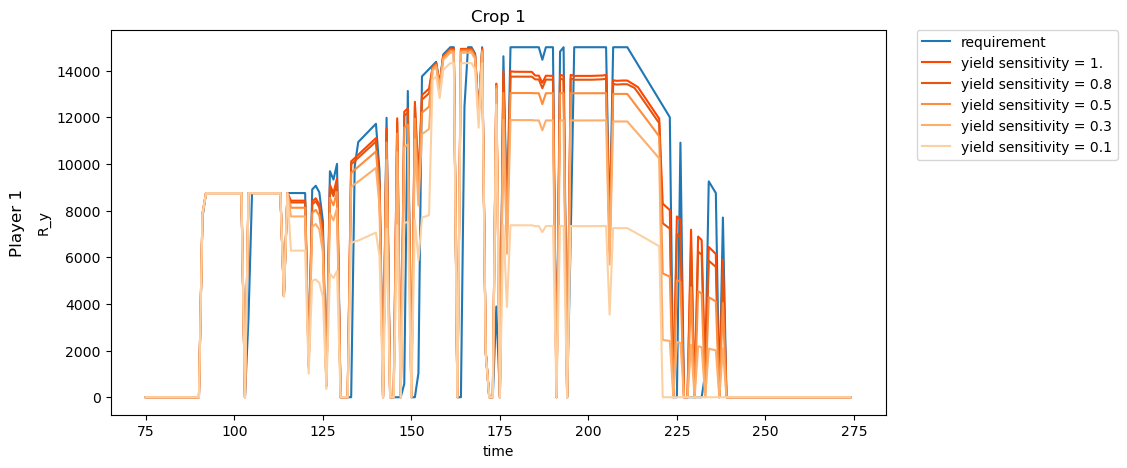

In [448]:
fig = plt.figure(figsize=(5+5,5))
ii = 0
c = 0
ax = fig.add_subplot(1, 1, 1)
if ii == 0:
    ax.set_title(f"Crop {c+1}")
ax.set_xlabel("time")
if c == 0:
    ax.set_ylabel("R_y")
    ax.annotate(f"Player {ii+1}", xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 10, 0),
        xycoords=ax.yaxis.label, textcoords='offset points',
        size='large', ha='center', va='center', rotation=90)
ax.plot(np.linspace(75, 274, 200), water_req[ii, c, 75:275], label='requirement')
# ax.plot(np.linspace(75, 274, 200), ET_min[ii, c, 75:275], c="cyan", alpha=0.5, label=f'tolerance\n(cost increase: +{tol})')
ax.plot(np.linspace(75, 274, 200), -crop_irrigation_ys_10[c, 75:275, ii], color=colors[-1], label='yield sensitivity = 1.')
ax.plot(np.linspace(75, 274, 200), -crop_irrigation_ys_8[c, 75:275, ii], color=colors[4], label='yield sensitivity = 0.8')
ax.plot(np.linspace(75, 274, 200), -crop_irrigation_ys_5[c, 75:275, ii], color=colors[5], label='yield sensitivity = 0.5')
ax.plot(np.linspace(75, 274, 200), -crop_irrigation_ys_3[c, 75:275, ii], color=colors[6], label='yield sensitivity = 0.3')
ax.plot(np.linspace(75, 274, 200), -crop_irrigation[c, 75:275, ii], color=colors[7], label='yield sensitivity = 0.1')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Pumping repartition

In [449]:
data_extra_well= np.load("run_data/run_20250623-143657/result_data.npz")
model_extra_well = IrrigationSchedulingModel("run_data/run_20250623-143657/model_parameters.json", boundary_condition="Constant Head")

In [450]:
player_pumping_3 = well_to_agent @ data_ys_3['q_rates']

n_well_extra = int(sum(np.hstack(model_extra_well.n_well_per_command)))
well_to_agent_extra = np.zeros((model_extra_well.n_agent, n_well_extra))
indices = np.array(list(zip(model_extra_well.well_to_agent.tolist(), range(n_well_extra)))).T
well_to_agent_extra[indices[0, :], indices[1, :]] = 1
player_pumping_extra = well_to_agent_extra @ data_extra_well['q_rates']

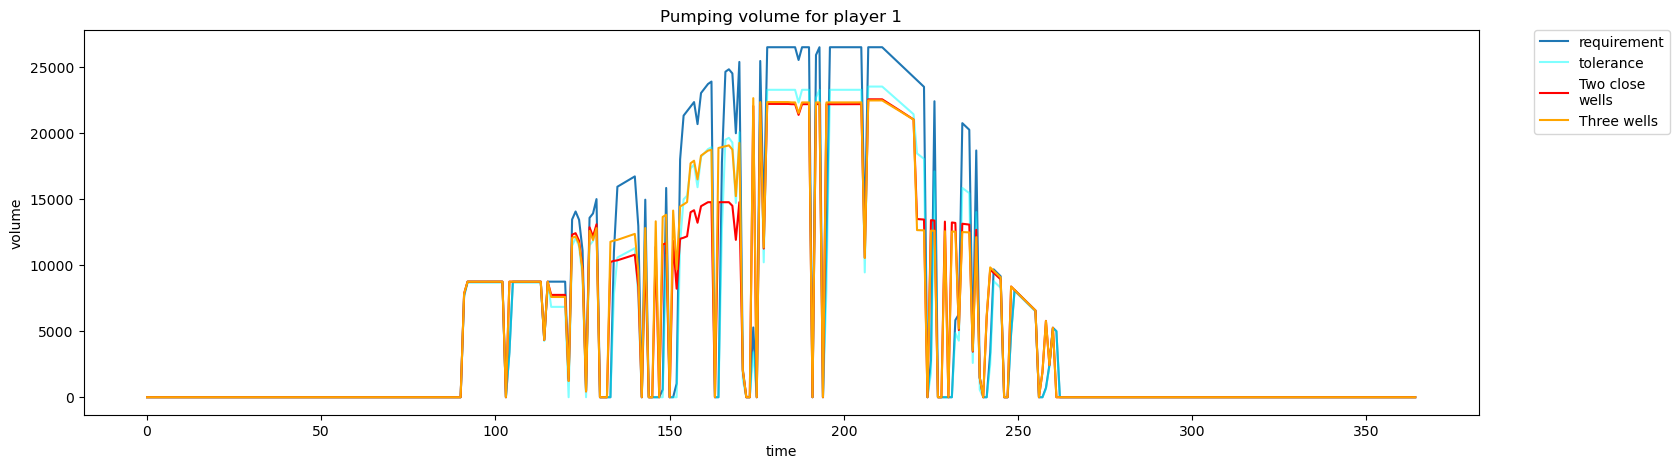

In [451]:
fig = plt.figure(figsize=(15+3,5))
ax = None
ii=0

ax = fig.add_subplot(1, 1, 1, sharey=ax)
ttl = f"Pumping volume for player {ii+1}"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("volume")
ax.plot(water_req[ii, :, :].sum(axis=0), label='requirement')
ax.plot(ET_min[ii, :, :].sum(axis=0), c="cyan", alpha=0.5, label='tolerance')
ax.plot(-player_pumping_3[ii, :], "r-", label='Two close\nwells')
ax.plot(-player_pumping_extra[ii, :], color="orange", label='Three wells')

ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [452]:
input_per_well = model.input_per_well @ data_ys_3['inputs']
input_per_well_extra = model_extra_well.input_per_well @ data_extra_well['inputs']

In [453]:
model.n_crops

4

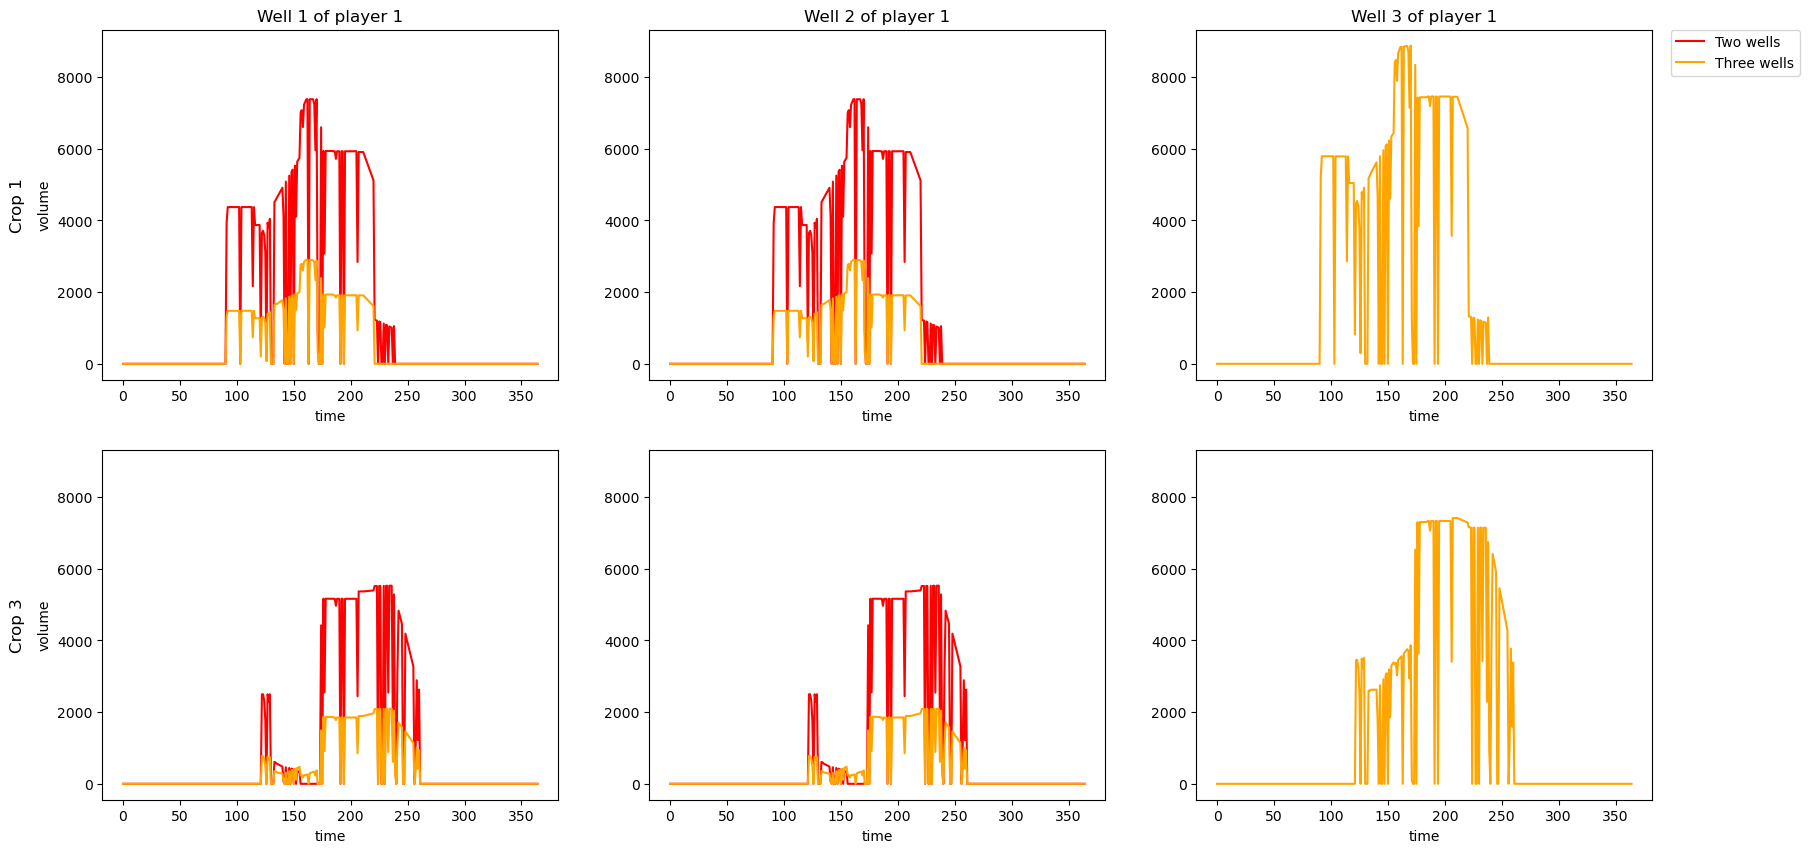

In [454]:
ii = 0
n_well_max = int(model_extra_well.n_well_per_command[ii].sum())

well_index = np.arange(np.hstack(model.n_well_per_command).sum())[model.well_to_agent==0]
well_index_extra = np.roll(np.arange(np.hstack(model_extra_well.n_well_per_command).sum())[model_extra_well.well_to_agent==0], -1)
crop_index = np.arange(model.n_crops, dtype=int)[cost_model.crop_repartition[:,ii] != 0]

fig = plt.figure(figsize=(15+5,crop_index.sum()*5))
ax = None
for w in range(n_well_max):
    for i, c in enumerate(crop_index):
        ax = fig.add_subplot(crop_index.sum(), n_well_max, n_well_max*i+w+1, sharey=ax)
        if i == 0:
            ttl = f"Well {w+1} of player {ii+1}"
            ax.set_title(ttl)
        ax.set_xlabel("time")
        if w == 0:
            ax.set_ylabel("volume")
            ax.annotate(f"Crop {c+1}", xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 5, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
        if w < n_well_max-1:
            ax.plot(-input_per_well[int(model.n_crops*well_index[w]+c), :], "r-", label='Two wells')
        ax.plot(-input_per_well_extra[int(model_extra_well.n_crops*well_index_extra[w]+c), :], "orange", label='Three wells')
        if i==0 and w==1:
            ax.legend(bbox_to_anchor=(2.24, 1), loc="upper left", borderaxespad=0)

TODO:
- Irrigation per crop for each player
- Repartition of pumping among wells (in the current setting: not much other choice than reduce pumping)
- Efficiency cost to compare with business as usual

Advantages:
- Of dynamic model:
    - Adaptive under-irrigation cost
    - Model of transient useful when modeling the rain (-> TODO: make more evident with explicit example)
- Of game-theoretical part:
    - Model interactions between player -> realistic pumping cost
        - Rather pump in far away wells
        - Reduce pumping in well close to neighbors
    - Can implement common policy constraints -> ??

# New irrigation plots

In [461]:
data = np.load("run_data/run_20250624-145931/result_data.npz")

In [463]:
player_pumping = well_to_agent @ data['q_rates']
rain = cost_model._get_available_water(0, 365)

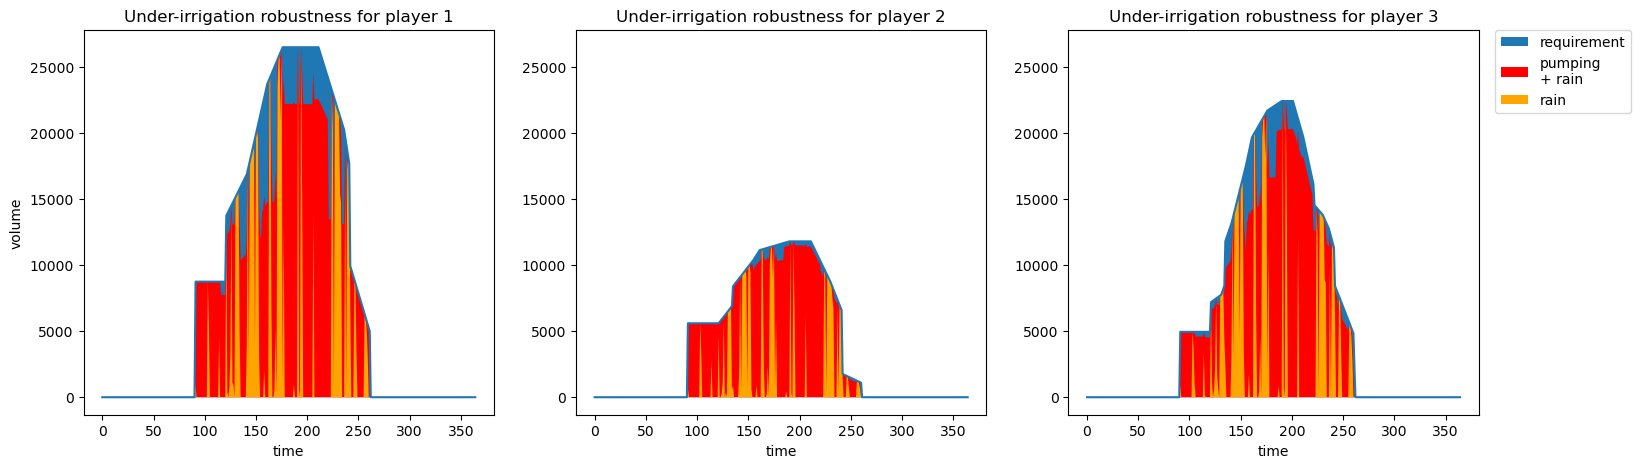

In [ ]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Under-irrigation robustness for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill((water_req+rain)[ii, :, :].sum(axis=0), label='requirement')
    ax.fill(-player_pumping[ii, :] + rain[ii,:,:].sum(axis=0), "r-", label='pumping\n+ rain')
    ax.fill(rain[ii,:,:].sum(axis=0), "orange", label='rain')
    # ax.plot((ET_min+rain)[ii, :, :].sum(axis=0), c="cyan", alpha=0.5, label=f'tolerance\n(cost increase: +{tol})')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Cost analysis

In [492]:
u = np.array([model.reorganize_input_per_well(data['inputs'][:,[k]]) for k in range(365)]).T
u = u.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops, 365))

In [524]:
pumping_cost = np.zeros((cost_model.n_agent, 365))
under_irrigation_cost = np.zeros((cost_model.n_agent, 365))
for v in range(cost_model.n_agent):
    input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v].T)[1]
    well_index = np.arange(np.hstack(model.n_well_per_command).sum(), dtype=int)[model.well_to_agent==v]
    for t in range(364):
        pumping_cost[v,t] = (-cost_model.extraction_cost[v] * (cost_model.top_head[input_indices] -\
            data['h_wells'][[well_index], t+1].T) * u[cost_model.well_to_agent==v,:,t].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = water_req[v, :, t] + u[cost_model.well_to_agent==v,:,t].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost[v,t] = \
            under_irrigation.T @ sp.diags(under_irrigation_weight[v,:,t].flatten()) @ under_irrigation.T
cost = pumping_cost + under_irrigation_cost

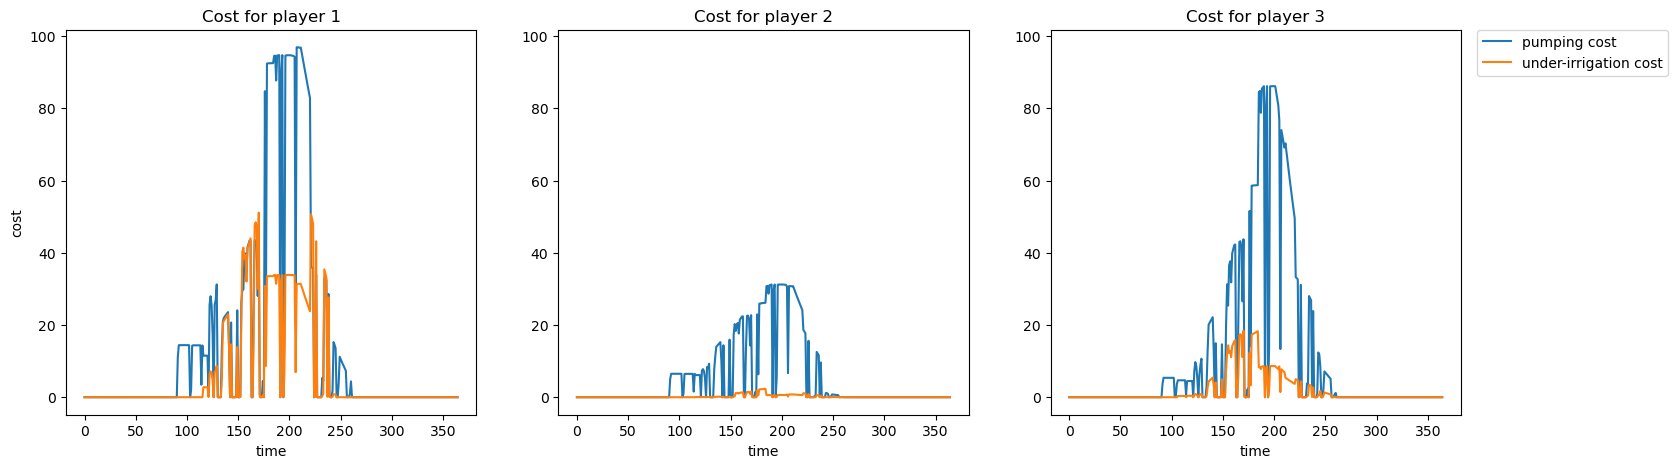

In [525]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(pumping_cost[ii, :], label='pumping cost')
    ax.plot(under_irrigation_cost[ii, :], label='under-irrigation cost')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

TODO: check at the controller level:
- Is first stage cost leading decision? i.e. does it dominate
- Could happen if the dynamics are very responsive

Thinking about it, in the previous experiments, the progressivity of the heads evolution was due to the constraint on the command. The latter was actually also discontinuous (to check).

Strange: around t.s. 200, constant pumping rate and constant heads --> dynamics are very responsive, no log curve as before ?

In [528]:
-player_pumping[0, 180:190], pumping_cost[0, 180:190]

(array([22207.34628059, 22207.26080935, 22207.18302002, 22207.11241504, 22207.06367283, 22187.55920274, 22187.30685925, 21377.8965845 , 22187.4745931 , 22188.14675394]),
 array([92.45419363, 92.46497361, 92.47468842, 92.4846255 , 92.49412128, 94.50493286, 94.55056349, 87.68606609, 94.61244827, 94.65726762]))

In [540]:
data['corrected_h_wells'][:,180:190]

array([[-21.67190115, -21.67557739, -21.68003231, -21.68403973, -21.68814214, -21.69203063, -22.53215542, -22.55024992, -21.35851767, -22.57511498],
       [-13.83284554, -13.83676165, -13.84103449, -13.84520024, -13.84929519, -13.85284478, -18.45038219, -18.50550208, -17.48495523, -18.61237571],
       [ -5.44082049,  -5.44892095,  -5.45774506,  -5.46623166,  -5.47457981,  -5.48297985,  -6.64340614,  -6.66633719,  -6.07195331,  -6.71031665],
       [-21.67190115, -21.67557739, -21.68003231, -21.68403973, -21.68814214, -21.69203063, -22.53215542, -22.55024992, -21.35851767, -22.57511498],
       [ -7.64547836,  -7.65399712,  -7.66342151,  -7.67230283,  -7.68137127,  -7.69008433,  -9.11424604,  -9.14418371,  -8.46263412,  -9.18979432]])

In [542]:
data['pred_avg_h_wells'][:,:4,180:190]

array([[[-21.67190115, -21.67557739, -21.68003231, -21.68403973, -21.68814214, -21.69203063, -22.53215542, -22.55024992, -21.35851767, -22.57511498],
        [-25.3431386 , -25.34620766, -25.34927714, -25.3523433 , -25.355406  , -26.04468113, -26.06058718, -24.75999313, -26.07540504, -26.09500858],
        [-25.35868848, -25.36174114, -25.36480264, -25.36785747, -26.05710634, -26.05773847, -24.75890228, -26.07749378, -26.09059631, -26.10802419],
        [-25.36634009, -25.369381  , -25.37244689, -26.06168061, -26.06229309, -24.75689318, -26.0762454 , -26.09073724, -26.10535209,   9.79607118]],

       [[-13.83284554, -13.83676165, -13.84103449, -13.84520024, -13.84929519, -13.85284478, -18.45038219, -18.50550208, -17.48495523, -18.61237571],
        [-21.30435802, -21.30990816, -21.31538397, -21.32070683, -21.32568946, -27.16615935, -27.23319716, -25.90066333, -27.37303661, -27.43920811],
        [-21.30668223, -21.31216038, -21.31749474, -21.3224836 , -27.16268909, -27.235878  , -25.9

In [544]:
data_30 = np.load("run_data/run_20250625-102102/result_data.npz")

In [548]:
data_30['corrected_h_wells'][:,175:190]

array([[  3.01511309,   9.98136303, -20.19964992,  -5.89480615, -21.63156013, -21.6718994 , -21.67557594, -21.68003157, -21.68403804, -21.68814077, -21.69203005, -22.53215408, -22.55024793, -21.35851569, -22.57511299],
       [  5.3233001 ,   9.99562908, -12.37872184,  -1.75237821, -13.8155301 , -13.83284406, -13.83676043, -13.84103387, -13.84519879, -13.849294  , -13.85284429, -18.45038175, -18.50550142, -17.48495457, -18.61237505],
       [  6.4460831 ,   9.98730771,  -4.59244236,   2.34002879,  -5.43714893,  -5.4408195 ,  -5.44892014,  -5.45774466,  -5.46623065,  -5.47457901,  -5.48297955,  -6.64340536,  -6.666336  ,  -6.07195214,  -6.71031549],
       [  3.01511309,   9.98136303, -20.19964992,  -5.89480615, -21.63156013, -21.6718994 , -21.67557594, -21.68003157, -21.68403804, -21.68814077, -21.69203005, -22.53215408, -22.55024793, -21.35851569, -22.57511299],
       [  6.02018601,   9.97341255,  -6.55292321,   1.20450121,  -7.57758551,  -7.6454794 ,  -7.65399797,  -7.66342193,  -7.

In [572]:
data_30['pred_avg_h_wells'][:,:4,175:190]

array([[[  3.01511309,   9.98136303, -20.19964992,  -5.89480615, -21.63156013, -21.6718994 , -21.67557594, -21.68003157, -21.68403804, -21.68814077, -21.69203005, -22.53215408, -22.55024793, -21.35851569, -22.57511299],
        [  9.95703825, -23.65948914,  -7.93248831, -25.24258524, -25.34008322, -25.34313469, -25.34620567, -25.34927254, -25.35233956, -25.35540443, -26.04467757, -26.0605819 , -24.75998785, -26.07539976, -26.09500331],
        [-23.67571307,  -7.87262877, -25.28656658, -25.31370499, -25.35563638, -25.35867937, -25.36173651, -25.36479195, -25.36784878, -26.05710276, -26.05773019, -24.75889002, -26.07748151, -26.09058404, -26.10801192],
        [ -7.87957936, -25.26012943, -25.33215217, -25.34357567, -25.36327394, -25.36631898, -25.36937028, -25.37242211, -26.06166087, -26.06228478, -24.75687398, -26.07621697, -26.0907088 , -26.10532364,   9.79606981]],

       [[  5.3233001 ,   9.99562908, -12.37872184,  -1.75237821, -13.8155301 , -13.83284406, -13.83676043, -13.8410338

In [573]:
Q, R, R_minus, M, L = cost_model.get_cost_matrices(175, 10)
controller.update_cost_matrices(Q, R, R_minus, M, L)
inputs, x_pred = controller.step(data_30['states'][:,[175]])

In [577]:
(inputs - data_30['inputs'][:, 175:185].T).max(), (inputs - data_30['inputs'][:, 175:185].T)[2,:]

(np.float64(15.225206505004735),
 array([-1.10935677e+00,  4.43831559e-16, -4.15296944e-01,  3.53022467e-16,  1.52252065e+01,  9.35586691e-18,  3.57198961e-18, -4.07053183e-17, -1.52080680e+01,  1.47709543e-01,  1.45297562e-17, -8.27174347e-17,  1.11955776e-01,  2.26119874e-12,  8.38212461e-02,  2.36451523e-01]))

In [578]:
q_rates = model.translate_input(data_30['inputs'][:, 174:185])

In [579]:
model.apply_head_correction(model.select_wells(x_pred), q_rates)

array([[  3.01511309,   9.95703858, -23.67595108,  -7.87884506, -25.26344681, -25.32195083, -25.34745751, -25.36036492, -25.36819671, -25.37459682, -25.38227106],
       [  5.3233001 ,  10.01423773, -19.49556282,  -5.44899321, -21.31777632, -21.30740748, -21.30432272, -21.30627124, -21.31045973, -21.31582373, -21.32226335],
       [  6.4460831 ,   9.9671349 ,  -7.67019397,   0.65788009,  -8.7263911 ,  -8.74706753,  -8.77096806,  -8.78712328,  -8.800103  ,  -8.81204968,  -8.82438971],
       [  3.01511309,   9.95703858, -23.67595108,  -7.87884506, -25.26344681, -25.32195083, -25.34745751, -25.36036492, -25.36819671, -25.37459682, -25.38227106],
       [  6.02018601,  10.01328959,  -9.74511276,  -0.38782943, -10.82361286, -10.82502681, -10.81915039, -10.82259432, -10.83012063, -10.83963095, -10.85066209]])

In [580]:
q_rates

array([[-2.47701026e+03,  2.32243789e-18, -1.06722970e+04, -5.62846233e+03, -1.11050993e+04, -1.11037144e+04, -1.11036717e+04, -1.11036297e+04, -1.11035898e+04, -1.11035548e+04, -1.11035313e+04],
       [-3.22949144e+03, -1.71099446e-17, -1.56134910e+04, -8.19492035e+03, -1.66282796e+04, -1.66335560e+04, -1.66363605e+04, -1.66391399e+04, -1.66418734e+04, -1.66445173e+04, -1.66469566e+04],
       [-1.41470542e+03, -6.97314282e-18, -5.59946467e+03, -2.90454052e+03, -5.93190385e+03, -5.91168640e+03, -5.91637720e+03, -5.92104800e+03, -5.92571019e+03, -5.93036204e+03, -5.93500307e+03],
       [-2.47701026e+03,  2.32243789e-18, -1.06722970e+04, -5.62846233e+03, -1.11050993e+04, -1.11037144e+04, -1.11036717e+04, -1.11036297e+04, -1.11035898e+04, -1.11035548e+04, -1.11035313e+04],
       [-1.06902299e+03, -9.71558893e+00, -4.07972642e+03, -2.20087218e+03, -4.39006459e+03, -4.41959005e+03, -4.42411779e+03, -4.42865081e+03, -4.43317715e+03, -4.43769871e+03, -4.44221002e+03]])

In [602]:
bold_row = 12
for i, row in enumerate(x_pred):
    if i == bold_row:
        print('\033[95m'+'%03s [%s]' % (i, ' '.join('%07s' % i.round(2) for i in row))+'\033[0m')
    print('%03s [%s]' % (i, ' '.join('%07s' % i.round(2) for i in row)))
# print(x_pred[:bold_row,:], '\n\033[95m', x_pred[bold_row,:], '\n\033[0m', x_pred[bold_row+1:,:])

  0 [   9.82    9.99     8.3    9.08     8.2    8.18    8.18    8.17    8.17    8.17    8.17]
  1 [   9.46   10.01    6.35    8.12    6.22    6.24    6.24    6.25    6.25    6.25    6.25]
  2 [   9.22    9.98    4.96    7.28    4.66    4.63    4.62    4.61    4.61     4.6     4.6]
  3 [   9.36   10.01    4.94    7.38    4.72    4.74    4.75    4.75    4.75    4.75    4.74]
  4 [   9.77    9.99    7.46    8.63     7.3    7.28    7.28    7.27    7.27    7.27    7.27]
  5 [   9.49   10.01    6.53    8.22    6.41    6.43    6.44    6.44    6.44    6.44    6.44]
  6 [   8.38    9.97    2.72    6.08     2.3    2.25    2.24    2.23    2.22    2.22    2.22]
  7 [   7.32   10.03   -2.13    3.69   -2.64    -2.6   -2.59   -2.58   -2.58   -2.58   -2.59]
  8 [   7.86    9.97   -2.07    3.56   -2.79   -2.84   -2.85   -2.87   -2.87   -2.88   -2.89]
  9 [   9.34   10.01    4.55    7.17     4.3    4.32    4.33    4.33    4.33    4.33    4.32]
 10 [   9.33    9.98    5.68    7.66    5.42    5.39    5.38

The seemingly non-importance of the horizon might be due to the fact that we can get to the system steady-state in only one time-step.

This observation seems in itself a bit weird.

In [604]:
x_pred[:,0].reshape(5,5)

array([[9.81639729, 9.46486301, 9.22470844, 9.35567083, 9.76707273],
       [9.48865964, 8.37599133, 7.32199718, 7.86078853, 9.33599161],
       [9.32734366, 7.61757411, 5.49212335, 7.089209  , 9.09238002],
       [9.48401262, 8.36030013, 7.35247819, 7.34037405, 9.07966113],
       [9.81197533, 9.43572854, 9.02243815, 8.55279154, 9.52782237]])

In [607]:
np.nonzero(model.well_to_cell.toarray())[0]

array([ 8, 12, 12, 13, 23])

In [613]:
(model.A @ x_pred[:,[0]]).reshape(5,5)

array([[0.00124638, 0.00481127, 0.00249255, 0.00481147, 0.00124617],
       [0.00481118, 0.00373902, 0.00962272, 0.00373866, 0.00481153],
       [0.00249278, 0.00962248, 0.00498515, 0.00962289, 0.00249237],
       [0.00481115, 0.00373907, 0.00962266, 0.00373871, 0.0048115 ],
       [0.0012464 , 0.00481122, 0.0024926 , 0.00481142, 0.0012462 ]])

In [611]:
(model.A @ x_pred[:,[0]] + model.C).reshape(5,5)

array([[ 9.99020149, 10.01550597,  9.98040278, 10.01550617,  9.99020129],
       [10.01550588,  9.97060436, 10.03101212,  9.97060401, 10.01550623],
       [ 9.98040301, 10.03101188,  9.96080561, 10.03101229,  9.9804026 ],
       [10.01550585,  9.97060441, 10.03101206,  9.97060406, 10.0155062 ],
       [ 9.99020152, 10.01550592,  9.98040284, 10.01550612,  9.99020132]])

In [612]:
model.C.reshape(5,5)

array([[ 9.98895512, 10.0106947 ,  9.97791023, 10.0106947 ,  9.98895512],
       [10.0106947 ,  9.96686535, 10.0213894 ,  9.96686535, 10.0106947 ],
       [ 9.97791023, 10.0213894 ,  9.95582046, 10.0213894 ,  9.97791023],
       [10.0106947 ,  9.96686535, 10.0213894 ,  9.96686535, 10.0106947 ],
       [ 9.98895512, 10.0106947 ,  9.97791023, 10.0106947 ,  9.98895512]])

Very low impact of the neighboring cells compared to impact of constant head condition.

The problem was: our aquifer was too small -> in the process of changing files it has been reduced from 1000\*1000 to 100\*100.

# Corrected grid dimensions

In [743]:
data = np.load("run_data/run_20250625-171059/result_data.npz")

In [744]:
player_pumping = well_to_agent @ data['q_rates']
rain = cost_model._get_available_water(0, 365)

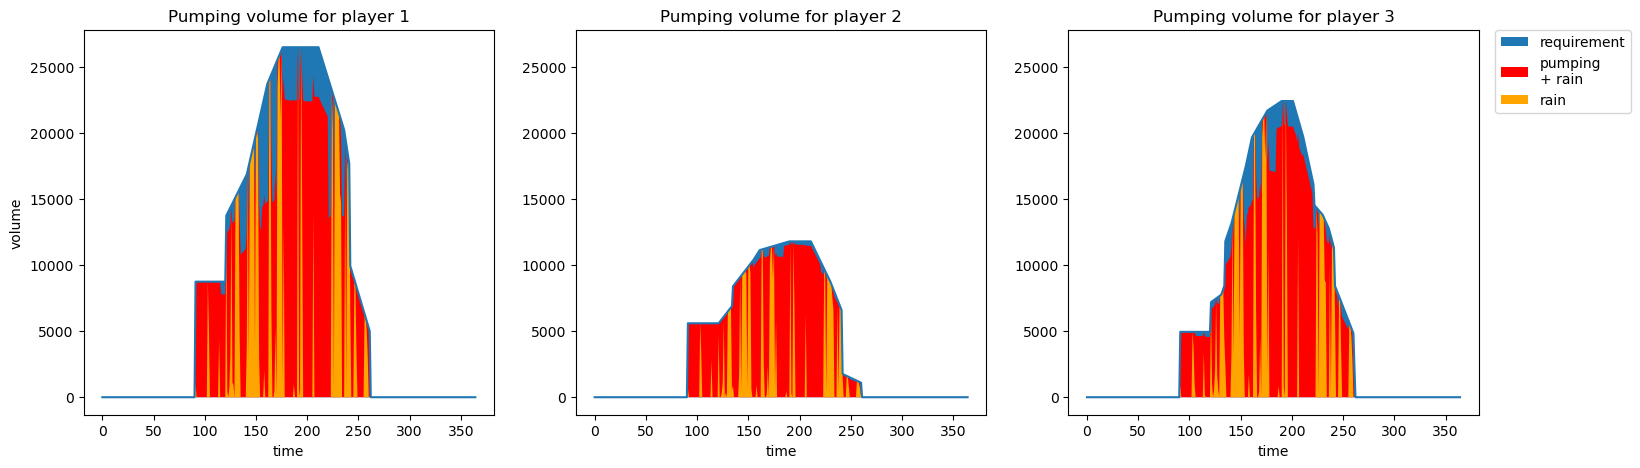

In [745]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Pumping volume for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill((water_req+rain)[ii, :, :].sum(axis=0), label='requirement')
    ax.fill(-player_pumping[ii, :] + rain[ii,:,:].sum(axis=0), "r-", label='pumping\n+ rain')
    ax.fill(rain[ii,:,:].sum(axis=0), "orange", label='rain')
    # ax.plot((ET_min+rain)[ii, :, :].sum(axis=0), c="cyan", alpha=0.5, label=f'tolerance\n(cost increase: +{tol})')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Cost analysis

In [746]:
water_req = cost_model._get_water_requirement(0, 365)

In [747]:
u = np.array([model.reorganize_input_per_well(data['inputs'][:,[k]]) for k in range(365)]).T
u = u.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops, 365))

In [748]:
pumping_cost = np.zeros((cost_model.n_agent, 365))
under_irrigation_cost = np.zeros((cost_model.n_agent, 365))
for v in range(cost_model.n_agent):
    input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v].T)[1]
    well_index = np.arange(np.hstack(model.n_well_per_command).sum(), dtype=int)[model.well_to_agent==v]
    for t in range(364):
        pumping_cost[v,t] = (-cost_model.extraction_cost[v] * (cost_model.top_head[input_indices] -\
            data['h_wells'][[well_index], t+1].T) * u[cost_model.well_to_agent==v,:,t].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = water_req[v, :, t] + u[cost_model.well_to_agent==v,:,t].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost[v,t] = \
            under_irrigation.T @ sp.diags(under_irrigation_weight[v,:,t].flatten()) @ under_irrigation.T
cost = pumping_cost + under_irrigation_cost

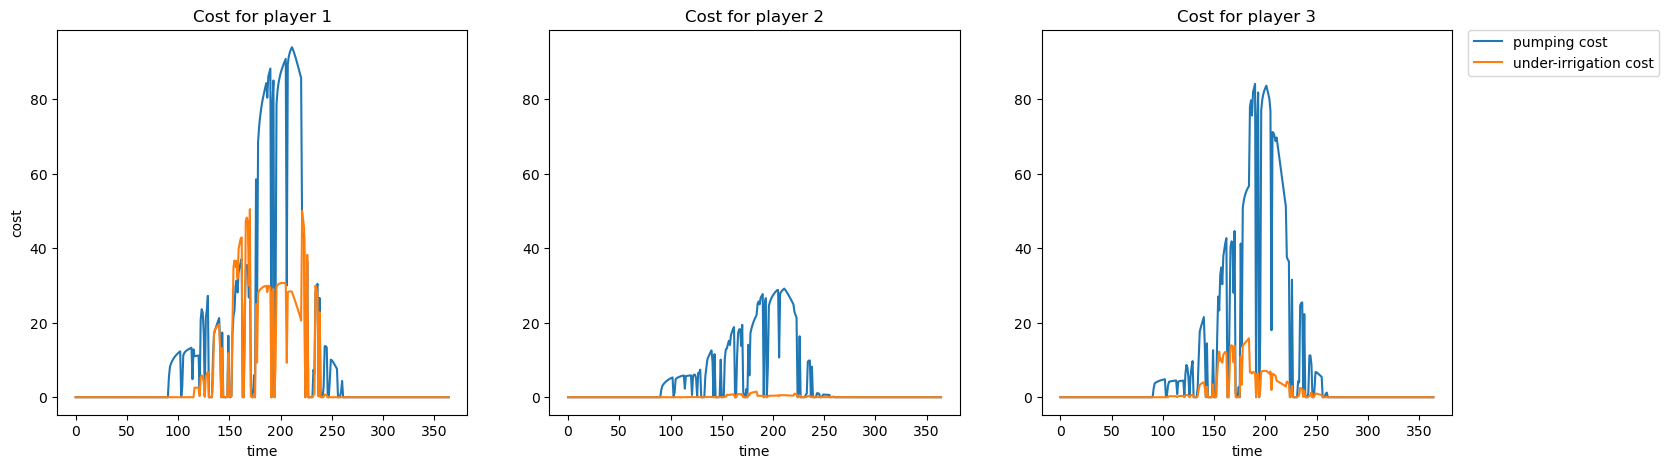

In [749]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(pumping_cost[ii, :], label='pumping cost')
    ax.plot(under_irrigation_cost[ii, :], label='under-irrigation cost')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [696]:
data_horizon_1 = np.load("run_data/run_20250625-145936/result_data.npz")
(data_horizon_1['inputs'] - data['inputs']).max(), (data_horizon_1['inputs'] - data['inputs']).min()

(np.float64(36.71763814334054), np.float64(-561.2702128046947))

In [697]:
del data_horizon_1

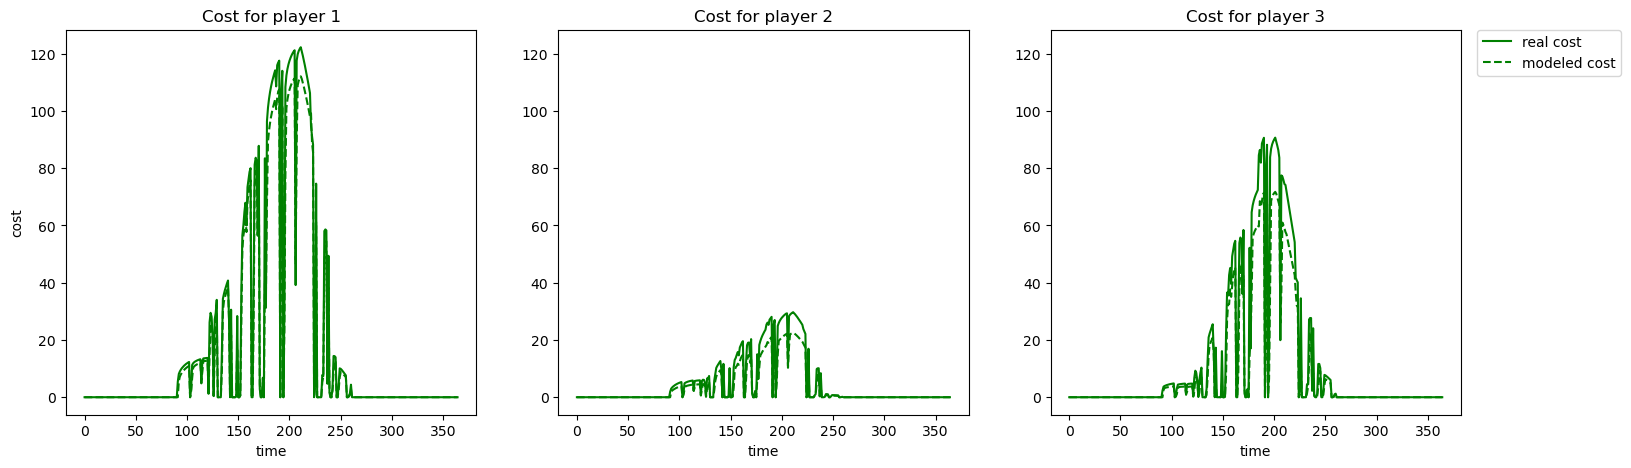

In [698]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(cost[ii, :], 'g-', label='real cost')
    ax.plot(-data['model_profit'][ii, :], 'g--', label='modeled cost')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [673]:
v=1
data['corrected_h_wells'].shape, np.arange(np.hstack(model.n_well_per_command).sum(), dtype=int)[model.well_to_agent==v]

((5, 365), array([2, 4]))

In [733]:
pumping_cost_corrected = np.zeros((cost_model.n_agent, 365))
under_irrigation_cost_corrected = np.zeros((cost_model.n_agent, 365))
for v in range(cost_model.n_agent):
    input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v].T)[1]
    well_index = np.arange(np.hstack(model.n_well_per_command).sum(), dtype=int)[model.well_to_agent==v]
    for t in range(364):
        pumping_cost_corrected[v,t] = (-cost_model.extraction_cost[v] * (cost_model.top_head[input_indices] -\
            data['corrected_h_wells'][[well_index], t+1].T) * u[cost_model.well_to_agent==v,:,t].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = water_req[v, :, t] + u[cost_model.well_to_agent==v,:,t].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost_corrected[v,t] = \
            under_irrigation.T @ sp.diags(under_irrigation_weight[v,:,t].flatten()) @ under_irrigation.T
cost_corrected = pumping_cost_corrected + under_irrigation_cost_corrected

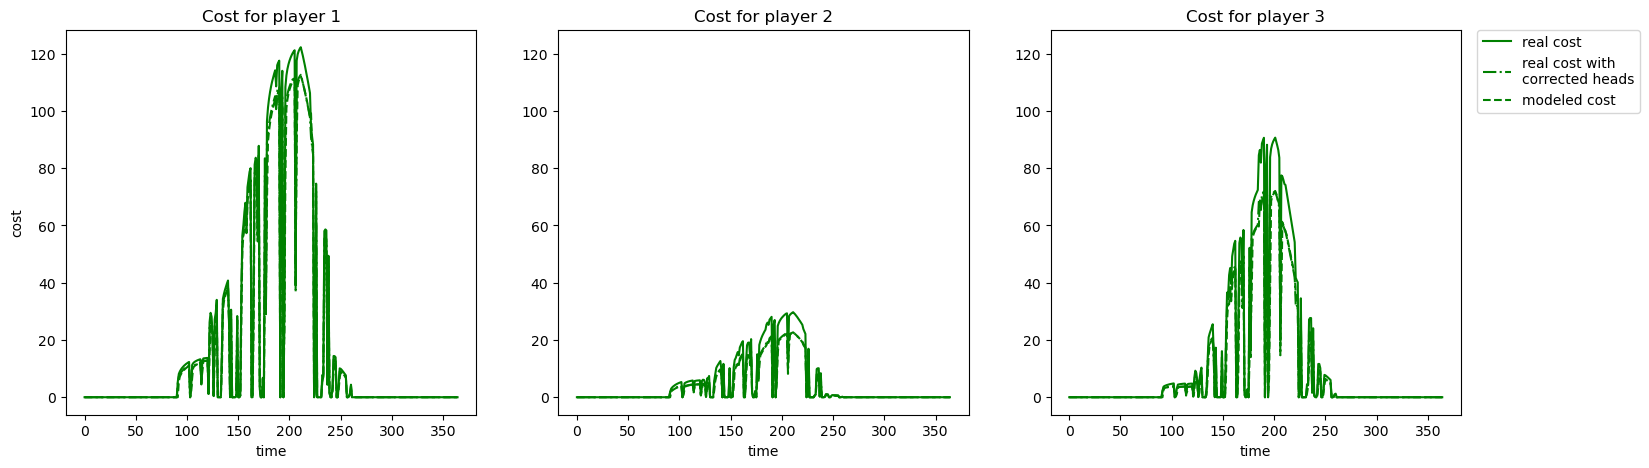

In [734]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(cost[ii, :], 'g-', label='real cost')
    ax.plot(cost_corrected[ii, :], 'g-.', label='real cost with\ncorrected heads')
    ax.plot(-data['model_profit'][ii, :], 'g--', label='modeled cost')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)